**Use Case at District Level ** (HOURLY)

*   Cooling demand data from Tanel (hourly time series)
*   Config- Snow Storage + Electric Chiller + air cooling
*   Performance analysis - only resource allocations,
*   Design and sizing -
*   Snow melt code - as per Montreal thesis
*   List item
*   Operational Strategy - snow cooling priority
*   Sensitivity analysis - NO                                                  
*   Time series - hourly






In [ ]:
import time as t
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime, timedelta

# Functions

In [ ]:
def Geometry(Prop):
    a, b, alpha, beta, d, h = Prop[:6]

    # Precompute common terms
    tan_beta = np.tan(beta)
    tan_alpha = np.tan(alpha)
    sin_beta = np.sin(beta)
    sin_alpha = np.sin(alpha)

    # Volume calculations
    term_surf = (a - 2.0 * h / tan_beta) * (b - 2.0 * h / tan_beta)
    sqrt_surf = np.sqrt((a * b) * term_surf)
    Vol_surf = (h / 3.0) * ((a * b) + term_surf + sqrt_surf)

    term_below = (a - 2.0 * d / tan_alpha) * (b - 2.0 * d / tan_alpha)
    sqrt_below = np.sqrt((a * b) * term_below)
    Vol_below = (d / 3.0) * ((a * b) + term_below + sqrt_below)

    Vol_tot = Vol_below + Vol_surf

    # Area calculations
    a_surf = term_surf + (h / sin_beta) * (2.0 * a + 2.0 * b + 2.0 * \
            (a - 2.0 * h / tan_beta) + 2.0 * (b - 2.0 * h / tan_beta)) / 2.0
    a_below = term_below + (d / sin_alpha) * ((2.0 * a + 2.0 * b) + \
            2.0 * (a - 2.0 * d / tan_alpha) + 2.0 * (b - 2.0 * d / tan_alpha)) / 2.0

    return [Vol_surf, Vol_below, Vol_tot, a_surf, a_below]


In [ ]:
def Melted_Volume(Temp, Rain, CDD, Prop, hour):
    a, b, alpha, beta, d, h, Dw, Ds, Ls, cw, lambda_i, lambda_g, thickness = Prop

    # Precompute common terms
    tan_beta = np.tan(beta)
    tan_alpha = np.tan(alpha)
    sin_beta = np.sin(beta)
    sin_alpha = np.sin(alpha)

    # Surface area
    if h > 0:
        A = (a - 2.0 * h / tan_beta) * (b - 2.0 * h / tan_beta) + (h / sin_beta) * \
            (2.0 * a + 2.0 * b + 2.0 * (a - 2.0 * h / tan_beta) + 2.0 * (b - 2.0 * h / tan_beta)) / 2.0
    else:
        A = (a - 2.0 * abs(h) / tan_alpha) * (b - 2.0 * abs(h) / tan_alpha)

    # Ground area
    Ag = (a - 2.0 * d / tan_alpha) * (b - 2.0 * d / tan_alpha) + (d / sin_alpha) * \
        ((2.0 * a + 2.0 * b) + 2.0 * (a - 2.0 * d / tan_alpha) + 2.0 * (b - 2.0 * d / tan_alpha)) / 2.0

    # Surface melt in hourly
    Q_surf = A * (lambda_i / thickness) * Temp if Temp > 0 else 0
    V_surf = (Q_surf / (Ls * Ds)) * 3600.0

    # Rain melt
    V_rain = ((Rain / 1000.0) * A * Dw * cw * Temp) / (Ls * Ds) if Temp > 0 else 0

    # Ground melt
    Q_ground = lambda_g * Ag * 2.0
    V_ground = (Q_ground / (Ls * Ds)) * 3600.0

    # Forced snow melt (with cooling)
    if hour > (2280) and hour < (6480):
      V_cool = Cool*3.6*10**6/(Ls * Ds) # conversion to flowrate m3
    else:
      V_cool = 0

    # Total snowmelt
    V_melt = V_surf + V_rain + V_ground + V_cool
    V_melt0 = V_surf + V_rain + V_ground

    return V_melt, V_melt0, V_surf, V_rain, V_ground, V_cool

In [ ]:
def findHeightNew(V, Prop):
    a = Prop[0]
    b = Prop[1]
    alpha = Prop[2]
    beta = Prop[3]
    d = Prop[4]

    Vol_below = (d / 3.0) * ((a * b) + (a - 2.0 * d / np.tan(alpha)) * (b - 2.0 * d / np.tan(alpha)) \
                + np.sqrt((a * b) * (a - 2.0 * d / np.tan(alpha)) * (b - 2.0 * d / np.tan(alpha))))

    if V > Vol_below:
        h_new = calculateHeight(V, Vol_below, a, b, beta)
    else:
        h_new = -calculateHeight(Vol_below - V, 0, a, b, alpha)

    return h_new

In [ ]:
def calculateHeight(V, V_offset, a, b, angle):
    # Calculate the height of the snow pile using the volume and offset volume (V_offset) as input
    h_max = np.tan(angle) * (a / 2) * 50.0  # 50 is a scaling factor
    Vol_matrix = np.array([(i / 100.0 / 3.0) * ((a * b) + (a - 2.0 * i / 100.0 / np.tan(angle)) * \
        (b - 2.0 * i / 100.0 / np.tan(angle)) + np.sqrt((a * b) * (a - 2.0 * i / 100.0 / np.tan(angle)) *\
        (b - 2.0 * i / 100.0 / np.tan(angle)))) for i in range(1, int(h_max) + 1)])
    k = np.polyfit(Vol_matrix, np.arange(1, int(h_max) + 1), 1) # Linear fit; equivalent to the depricated 'regression' function in Modelica
    # Corrected formula: k[0] is (index / volume), so k[0] * (V - V_offset) gives index difference
    # Divide by 100.0 to convert this index difference into meters
    h = k[0] * (V - V_offset) / 100.0
    return h

# MAIN CODE

In [ ]:
# Load input data
filename1 = 'Data_Tallinn_DistrictLevel_hourly.xlsx'
Table_data = pd.read_excel(filename1)
print('\t Input data loaded successfully.')

Vf = np.zeros(6) # Is it needed in this block?
Tair = Table_data.iloc[:, 2].values  # air temp [ºC]
P = Table_data.iloc[:, 3].values  # Total Rain [mm]
D = Table_data.iloc[:, 4].values  # load [kWh]
E = Table_data.iloc[:, 5].values  # Ele cost [EUR]
s = Tair.shape # to get num of days i.e 8760
P[np.isnan(P)] = 0
print('\t Initialization complete.')


	 Input data loaded successfully.
	 Initialization complete.


In [ ]:
from os import CLD_DUMPED
# Start timer
start_time = t.time()

# Initialize properties and load weather data
print('	Initializing properties and loading weather data...')
a = 40.0  # Short side [m]
b = 70.0  # Long side [m]
alpha_degrees = 45.0  # Slope angle below surface
beta_degrees = 30.0  # Slope angle above surface
d = 2.0  # Pit depth [m]
h = 4.0  # Pile height [m]
beta = beta_degrees * np.pi / 180.0  # [rad]
alpha = alpha_degrees * np.pi / 180.0  # [rad]
Dw = 1000.0  # Density of water [kg m-3]
Ds = 750.0  # Density of snow [kg m-3]
Ls = 334000.0  # Latent heat of fusion [J kg-1]
cw = 4185.0  # Heat capacity [J kg-1 K-1]
lambda_i = 0.1  # Sawdust thermal conductivity [W m-1 K-1]
lambda_g = 1.0  # Ground thermal conductivity [W m-1 K-1]
thickness = 0.1  # Insulation layer thickness
Prop = [a, b, alpha, beta, d, h, Dw, Ds, Ls, cw, lambda_i, lambda_g, thickness]
Prop0 = Prop.copy()
Prop0 = Prop.copy()

# Calculate initial geometry
Geo = Geometry(Prop)
Vi = Geo[0] + Geo[1]   # Initial volume of snow
Vi0 = Geo[0] + Geo[1]  # Initial volume of snow

mass = Vi * Ds

print(f"\n total volume:{Vi0}\n")

# Main loop with cooling
print('	Starting main loop with cooling...')
num_of_hrs = s[0]
Vf2 = np.zeros((len(Vf), num_of_hrs))  # Preallocating for speed
Vnew2 = np.zeros(num_of_hrs)  # Preallocating for speed
storeh = np.zeros(num_of_hrs)  # Preallocating for speed

for i in range(s[0]):
    Temp = Tair[i]
    Rain = P[i]
    Cool = D[i]
    hour = i + 1

    V_melt, V_melt0, V_surf, V_rain, V_ground, V_cool = Melted_Volume(Temp, Rain, Cool, Prop, hour)

    Vf2[:, i] = [V_melt, V_melt0, V_surf, V_rain, V_ground, V_cool]

    # Calculate new volume
    current_Vi = Vi - Vf2[0, i]  # NB! Vf2[0, i] = V_melt

    # Cap volume and height at zero if melted completely
    if current_Vi <= 0:
        Vi = 0
        h_new = 0
    else:
        Vi = current_Vi
        h_new = findHeightNew(Vi, Prop)

    Vnew2[i] = Vi
    storeh[i] = h_new

    Prop[5] = h_new

print('	Main loop with cooling completed.')

# Main loop without cooling
print('	Starting main loop without cooling...')
Vf0 = np.zeros((len(Vf), num_of_hrs))  # Preallocating for speed
Vnew0 = np.zeros(num_of_hrs)  # Preallocating for speed
storeh0 = np.zeros(num_of_hrs)  # Preallocating for speed

for i in range(s[0]):
    Temp = Tair[i]
    Rain = P[i]
    hour = i + 1

    V_melt, V_melt0, V_surf, V_rain, V_ground, V_cool = Melted_Volume(Temp, Rain, 0, Prop0, hour)

    Vf0[:, i] = [V_melt, V_melt0, V_surf, V_rain, V_ground, V_cool]

    # Calculate new volume
    current_Vi0 = Vi0 - Vf0[1, i]  # NB! Vf0[1, i] = V_melt0

    # Cap volume and height at zero if melted completely
    if current_Vi0 <= 0:
        Vi0 = 0
        h_new0 = 0
    else:
        Vi0 = current_Vi0
        h_new0 = findHeightNew(Vi0, Prop0)

    Vnew0[i] = Vi0
    storeh0[i] = h_new0
    Prop0[5] = h_new0
print('	Main loop without cooling completed.')

# End timer
end_time = t.time()
print(f"\nElapsed time for calculations: {end_time-start_time:.4e} sec.\n")

# Extract daily variations of pile height and volume to Excel
daily_variations_df = pd.DataFrame({
    'Day': np.arange(1, num_of_hrs + 1),
    'Pile_Height_With_Cooling_m': storeh,
    'Pile_Volume_With_Cooling_m3': Vnew2,
    'Pile_Height_Without_Cooling_m': storeh0,
    'Pile_Volume_Without_Cooling_m3': Vnew0
})

output_filename_variations = 'snow_pile_variations_hourly.xlsx'
daily_variations_df.to_excel(output_filename_variations, index=False)
print(f"Daily snow pile variations exported to '{output_filename_variations}'")

# daily variation of heat leakages
daily_heat_leakage_df = pd.DataFrame({
    'Day': np.arange(1, num_of_hrs + 1),
    'Surface_Leakage_With_Cooling_m3': Vf2[2,:],
    'Rain_Leakage_With_Cooling_m3': Vf2[3,:],
    'Ground_Leakage_With_Cooling_m3': Vf2[4,:],
    'ColdSupply_Leakage_With_Cooling_m3': Vf2[5,:]
})

output_filename_heat_leakage = 'heat_leakage_variations_hourly.xlsx'
daily_heat_leakage_df.to_excel(output_filename_heat_leakage, index=False)
print(f"Daily heat leakage variations exported to '{output_filename_heat_leakage}'")

	Initializing properties and loading weather data...

 total volume:13563.622911528777

	Starting main loop with cooling...
	Main loop with cooling completed.
	Starting main loop without cooling...
	Main loop without cooling completed.

Elapsed time for calculations: 6.8079e+01 sec.

Daily snow pile variations exported to 'snow_pile_variations_hourly.xlsx'
Daily heat leakage variations exported to 'heat_leakage_variations_hourly.xlsx'


Design and Sizing

In [ ]:
###################COOLING DEMAND#################################
store_cd = D
total_cd= sum(D)/1000 # kWh to MWh conversion
peak_power = max(store_cd)
high_power = peak_power*0.80
avg_power = np.average(store_cd)

print(f"\n Cooling Demand Profile ")
print(f"  peak cooling load {max(store_cd):.2f} kW")
print(f"  average cooling load {np.average(store_cd):.2f} kW")
print(f"  total cooling demand: {total_cd:.2f} MWh")

# Count hours where cooling load is more than 80% of peak value
hrs_above_highP = np.sum(store_cd > high_power)
print(f" Number of hours with cooling load > 80% peak : {hrs_above_highP}")

###################SNOW STORAGE#################################

# setting the max. amount of chilled water that can be extracted
Vi1 = Geo[0] + Geo[1]  # Initial volume of snow
dis_cap_snow = peak_power # kW

# snow properties
rho_snow = 750     # kg/m^3 (typical density)
enth_snow = 0.0926 # kWh/kg enthalpy of fusion
Ls = 334000.0  # Latent heat of fusion [J kg-1]

vol_dis_cap = dis_cap_snow*3.6*10**6/(Ls * rho_snow) # conversion to flowrate m3
sp_cool_stored =  rho_snow * enth_snow # kWh/m3
max_cooling_cap = dis_cap_snow

# Checking pipe velocity (0.8 m/s to 2.0 m/s)
dia_pipe = 0.2 # m
area_pipe = (3.14 * (dia_pipe/2)**2)
vel_pipe = (vol_dis_cap/(60*60)) / area_pipe

print(f"\n Snow Storage ")
print(f"  discharge capacity: {dis_cap_snow:.2f} kWh/h")
print(f"  max hourly cooling output from snow sorage: {max_cooling_cap:.2f} kW")
print(f"  flow rate for discharge capacity: {vol_dis_cap:.2f} m^3/h")
print(f"  estimation of pipe velocity : {vel_pipe:.2f} m/s")

###################ELECTRIC CHILLER#################################
T_chiller_evap = 280  # K ie 7 deg cel
T_chiller_cond = 308  # K i.e 35 deg cel
delta_T_chiller = T_chiller_cond - T_chiller_evap

# Calculating COP value based on Carnot value (45-55%)
COP_Carnot = T_chiller_evap/delta_T_chiller
COP_Chiller = COP_Carnot * 0.55

# Assume chiller capacity is 80% of peak cooling power
chiller_cap = peak_power*0.80

print(f"\n Electric Chiller ")
print(f"  Carnot COP: {COP_Carnot} unitless")
print(f"  Actual COP: {COP_Chiller} unitless")
print(f"  Chiller capacity: {chiller_cap:.2f} kW")



 Cooling Demand Profile 
  peak cooling load 941.70 kW
  average cooling load 195.62 kW
  total cooling demand: 1713.67 MWh
 Number of hours with cooling load > 80% peak : 105

 Snow Storage 
  discharge capacity: 941.70 kWh/h
  max hourly cooling output from snow sorage: 941.70 kW
  flow rate for discharge capacity: 13.53 m^3/h
  estimation of pipe velocity : 0.12 m/s

 Electric Chiller 
  Carnot COP: 10.0 unitless
  Actual COP: 5.5 unitless
  Chiller capacity: 753.36 kW


Operational Stretegy and Resource Allocations

In [ ]:
hour_Vmelt_zero = -1
for idx, val in enumerate(Vnew2):
    if val <= 0:
        hour_Vmelt_zero = idx + 1 # +1 because idx is 0-based and day is 1-based
        break

if hour_Vmelt_zero != -1:
    print(f"Vnew2 became zero or negative on day: {hour_Vmelt_zero}")
else:
    print("Vnew2 never became zero or negative during the cooling season.")

avg_ele_price = np.mean(E)/1000
print(f"\n Average electricity price: {avg_ele_price:.2f} EUR/kWh")

# Arrays to store the contribution (daily) from each source
results_snow_used = np.zeros(num_of_hrs)
results_chiller_load = np.zeros(num_of_hrs) # Chiller directly meeting load
results_ele_chiller_total_cost = np.zeros(num_of_hrs) # Daily electricity cost for chiller
results_air_cooling= np.zeros(num_of_hrs)
results_load_unmet = np.zeros(num_of_hrs)

for i in range(num_of_hrs):

    hourly_temp_air = Tair[i]

    if (hourly_temp_air < 5):
        results_air_cooling[i] = store_cd[i]
        hourly_cooling_demand = 0
    else:
        hourly_cooling_demand = store_cd[i]

    hourly_electricity_price = E[i]/1000
    remaining_demand = hourly_cooling_demand
    snow_cool_avail = Vnew2[i] * sp_cool_stored

    # Store daily contributions for current day
    current_hour_snow_used = 0
    current_hour_chiller_load = 0
    current_hour_chiller_ele_cost = 0

    # 1. Prioritize Snow Cooling (if available and Vnew2 > 0)
    # Snow is available if Vnew2 is still positive, and before day_Vmelt_zero (if it occurred)
    # Also, snow cooling is only available from day 120 (i=2280)
    if (i >= 2280 and i < hour_Vmelt_zero - 1):
        snow_to_meet_demand = min(remaining_demand, max_cooling_cap, snow_cool_avail)
        current_hour_snow_used = snow_to_meet_demand
        remaining_demand -= current_hour_snow_used

    # If demand still exists after snow, use chiller
    chiller_amount = min(remaining_demand, chiller_cap)
    current_hour_chiller_load += chiller_amount
    current_hour_chiller_ele_cost += chiller_amount / COP_Chiller * hourly_electricity_price
    remaining_demand -= chiller_amount

    # Update results for the day
    results_snow_used[i] = current_hour_snow_used
    results_chiller_load[i] = current_hour_chiller_load
    results_ele_chiller_total_cost[i] = current_hour_chiller_ele_cost
    results_load_unmet[i] = max(0, remaining_demand) # Ensure unmet load isn't negative

# Overall contribution from each source (MWh) and total cost
snow_contribution = np.sum(results_snow_used)/1000
chiller_to_load_MWh = np.sum(results_chiller_load)/1000
total_chiller_ele_cost = np.sum(results_ele_chiller_total_cost)
total_load_unmet = np.sum(results_load_unmet)/1000
total_air_cooling = np.sum(results_air_cooling)/1000

# Print results
print(f"\n Energy Balance Analysis with Optimized Dispatch")
print(f"\t Snow Storage (MWh): {snow_contribution:.2f}")
print(f"\t Chiller to load (MWh): {chiller_to_load_MWh:.2f}")
print(f"\t Total chiller electricity cost: {total_chiller_ele_cost:.2f} EUR")
print(f"\t Total air cooling (MWh): {total_air_cooling:.2f}")
print(f"\t Total load unmet (MWh): {total_load_unmet:.2f}")

# Prepare data for Excel export
daily_contributions_df = pd.DataFrame({
    'Hour': np.arange(1, num_of_hrs + 1),
    'Cooling_Demand_kWh': store_cd,
    'Snow_Used_kWh': results_snow_used,
    'Chiller_Direct_Load_kWh': results_chiller_load,
    'Chiller_Electricity_Cost_EUR': results_ele_chiller_total_cost,
    'Load_Unmet_kWh': results_load_unmet,
    'Air_Cooling_kWh': results_air_cooling,
    'Electricity_Price_EUR_kWh': E
})

# Export to Excel
output_filename = 'hourly_cooling_contributions.xlsx'
daily_contributions_df.to_excel(output_filename, index=False)
print(f"\nDaily cooling contributions exported to '{output_filename}'")

Vnew2 became zero or negative on day: 5009

 Average electricity price: 0.08 EUR/kWh

 Energy Balance Analysis with Optimized Dispatch
	 Snow Storage (MWh): 739.21
	 Chiller to load (MWh): 460.16
	 Total chiller electricity cost: 5994.09 EUR
	 Total air cooling (MWh): 511.88
	 Total load unmet (MWh): 2.42

Daily cooling contributions exported to 'hourly_cooling_contributions.xlsx'


Performance Analysis

In [ ]:
total_cooling_demand_MWh = total_cd # from sum(D)/1000

# fraction
snow_fraction = (snow_contribution / total_cooling_demand_MWh) * 100
chiller_fraction = (chiller_to_load_MWh / total_cooling_demand_MWh) * 100

total_ele_snow = snow_contribution * 0.06 # in MWh, 0.06 is assumed to be an electricity factor for snow system
total_ele_chiller = chiller_to_load_MWh / COP_Chiller # discharging the tank
total_ele_overall = total_ele_snow + total_ele_chiller # in MWh

# COP component, overall
COP_snowstore = snow_contribution / total_ele_snow if total_ele_snow != 0 else 0
COP_chiller = (chiller_to_load_MWh) / total_ele_chiller if total_ele_chiller != 0 else 0 #  load + tank
COP_overall = total_cooling_demand_MWh / total_ele_overall if total_ele_overall != 0 else 0

# primary energy consumption
PEF_ele = 2 # primary energy factor for electricity in Estonia
PEC_ann = total_ele_overall * PEF_ele # in MWh


# Economic KPIs - without performance degradation
lifetime = 20
capex_snowpit = Vi1 * 25 # EUR/m3 (Vi1 is initial volume m3)
capex_chiller = chiller_cap * 100 # EUR/kW (chiller_cap is kW)
total_capex = capex_snowpit + capex_chiller

cost_ele = total_ele_overall * 1000 * avg_ele_price # EUR/year - shortcoming
OM_yr = total_capex * 0.02

Levelised_Cost = (total_capex + OM_yr*lifetime + cost_ele*lifetime) / (total_cooling_demand_MWh * lifetime) # EUR/MWh

# Check results
print(f"Snow Cooling Fraction: {snow_fraction:.2f}")
print(f"Chiller Fraction: {chiller_fraction:.2f}")
print(f"COP Snow Store: {COP_snowstore:.2f}")
print(f"COP Chiller: {COP_chiller:.2f}")
print(f"COP Overall: {COP_overall:.2f}")
print(f"PEC Annual: {PEC_ann:.2f} MWh")

print(f"\nAnnual elec cost: {cost_ele:.2f} EUR")
print(f"ele: {total_ele_overall:.2f} MWh")
print(f"Levelised Cost of Cooling (LCOC): {Levelised_Cost:.2f} €/MWh")

Snow Cooling Fraction: 43.14
Chiller Fraction: 26.85
COP Snow Store: 16.67
COP Chiller: 5.50
COP Overall: 13.39
PEC Annual: 256.04 MWh

Annual elec cost: 10289.49 EUR
ele: 128.02 MWh
Levelised Cost of Cooling (LCOC): 22.93 €/MWh


Plots snow storage level

Plotting results...


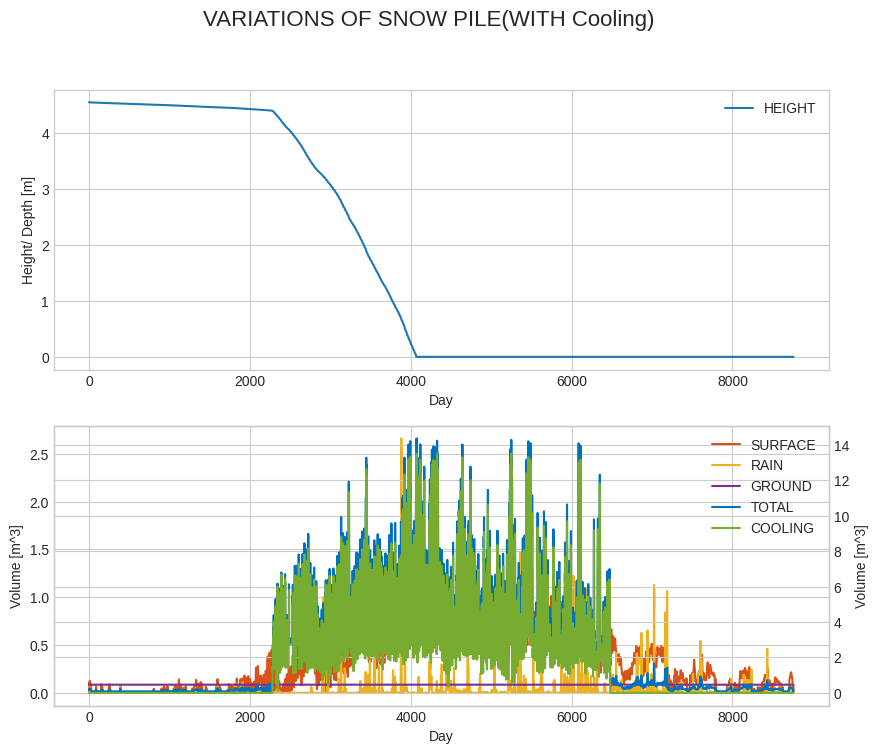

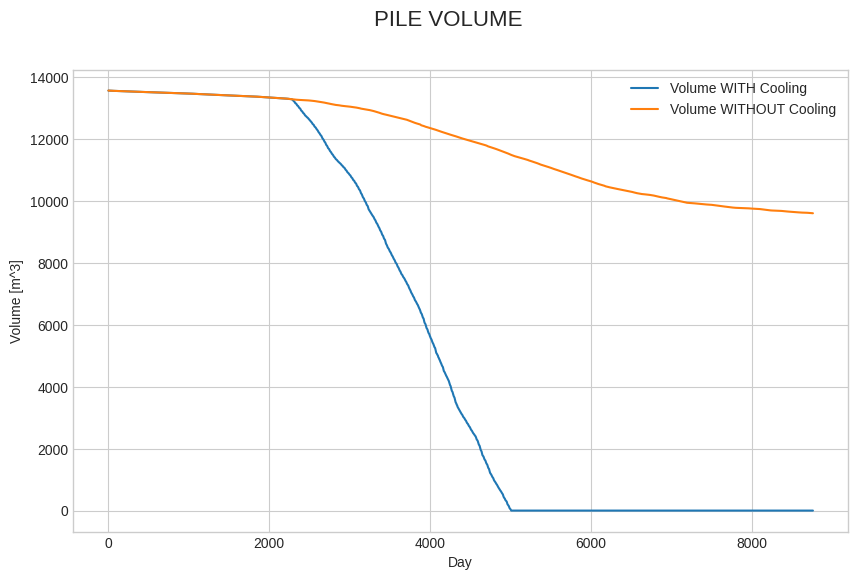

Plotting completed.


In [ ]:
# Plotting results
print('Plotting results...')

# Plot Figure 1
f1, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))
f1.suptitle('VARIATIONS OF SNOW PILE(WITH Cooling)', fontsize=16)

time = np.arange(1, num_of_hrs + 1)
storeh_positive = storeh.copy()
storeh_positive[storeh_positive < 0] = 0
ax1.plot(time, storeh_positive) # Plot only positive height values
ax1.set_ylabel('Height/ Depth [m]')
ax1.set_xlabel('Day')
ax1.grid(True)
ax1.legend(['HEIGHT'])

# Plot Figure 2
data = Vf2.T
# Ensure all volume components are non-negative for plotting
data_positive = np.maximum(data, 0)

# 'SURFACE', 'RAIN', 'GROUND' on the primary y-axis
ax2.plot(time, data_positive[:, 2], color='#D95319', label='SURFACE')
ax2.plot(time, data_positive[:, 3], color='#EDB120', label='RAIN')
ax2.plot(time, data_positive[:, 4], color='#7E2F8E', label='GROUND')
ax2.set_ylabel('Volume [m^3]')
ax2.set_xlabel('Day')
ax2.grid(True)

# Secondary y-axis for 'TOTAL' and 'COOLING'
ax2b = ax2.twinx()
ax2b.plot(time, data_positive[:, 0], color='#0072BD', label='TOTAL')
ax2b.plot(time, data_positive[:, 5], color='#77AC30', label='COOLING')
ax2b.set_ylabel('Volume [m^3]')

# Combine legends from both axes
lines, labels = ax2.get_legend_handles_labels()
lines2, labels2 = ax2b.get_legend_handles_labels()
ax2b.legend(lines + lines2, labels + labels2, loc='upper right')

# Plot Figure 3
f2, ax3 = plt.subplots(figsize=(10, 6))
f2.suptitle('PILE VOLUME', fontsize=16)

i = np.where(Vnew2 < 0)[0]
if len(i) == 0:
    ax3.plot(time, Vnew2, label='Volume WITH Cooling')
else:
    Vnew2TOP = Vnew2.copy()
    Vnew2TOP[i[0]:] = 0
    ax3.plot(time, Vnew2TOP, label='Volume WITH Cooling')

i = np.where(Vnew0 < 0)[0]
if len(i) == 0:
    ax3.plot(time, Vnew0, label='Volume WITHOUT Cooling')
else:
    Vnew0TOP = Vnew0.copy()
    Vnew0TOP[i[0]:] = 0
    ax3.plot(time, Vnew0TOP, '.', label='Volume WITHOUT Cooling')

ax3.set_ylabel('Volume [m^3]')
ax3.set_xlabel('Day')
ax3.grid(True)
ax3.legend()

plt.show()
print('Plotting completed.')

Plot system level

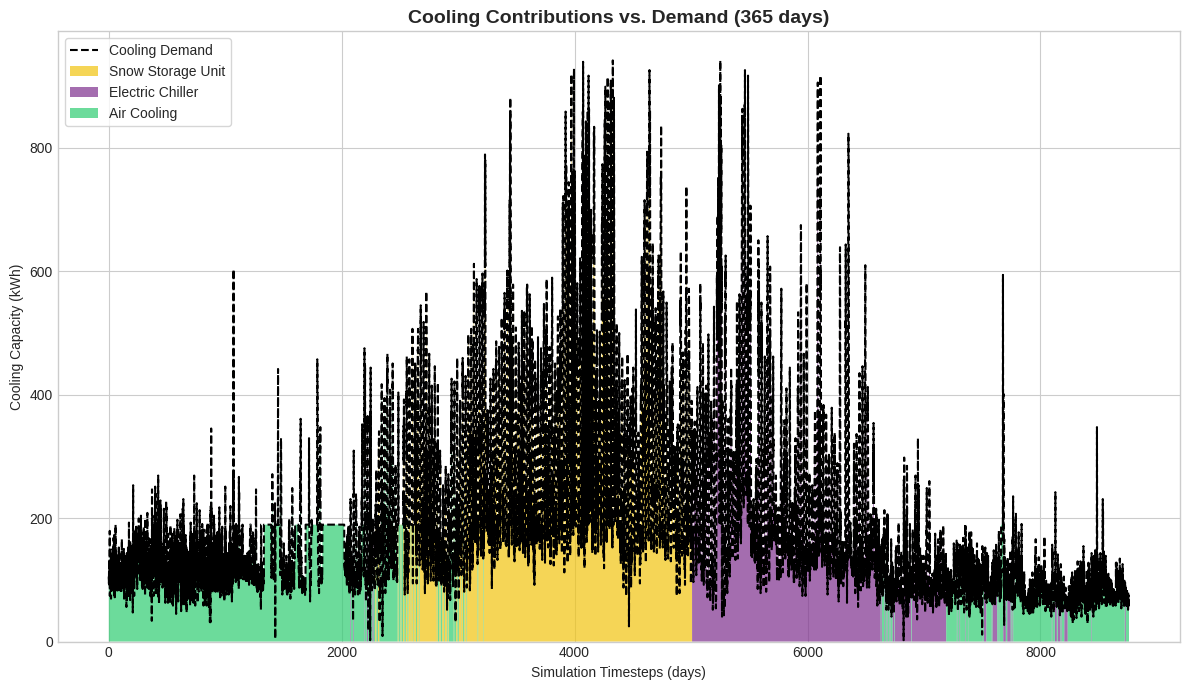

In [ ]:
import matplotlib.pyplot as plt
import numpy as np


#Plot Figure 2
plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(12, 7))
time = np.arange(1, num_of_hrs + 1)

# Plot cooling demand as a line plot
ax.plot(time, store_cd, label='Cooling Demand', color='black', linestyle='--')

ax.stackplot(
    time,
    results_snow_used,
    results_chiller_load,
    results_air_cooling,
    labels=['Snow Storage Unit', 'Electric Chiller', 'Air Cooling'],
    colors=['#F1C40F','#7E2F8E', '#2ECC71'],
    alpha=0.7
)

ax.set_title('Cooling Contributions vs. Demand (365 days)', fontsize=14, fontweight='bold')
ax.set_xlabel('Simulation Timesteps (days)')
ax.set_ylabel('Cooling Capacity (kWh)')
ax.legend(loc='upper left', frameon=True)
ax.set_ylim(bottom=0) # Ensure y-axis starts at 0
ax.grid(True)

plt.tight_layout()
plt.show()